# Feature Engineering — Demo

**Course:** Machine Learning Foundation  
**Dataset:** Ames Housing Data

Feature engineering adalah proses membuat atau mengubah fitur agar lebih berguna untuk analisis atau pemodelan. Notebook ini mencakup pemeriksaan data, encoding kategori, transformasi log, fitur interaksi, dan fitur polinomial.

## 1. Import library dan baca data

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import PolynomialFeatures

sns.set_theme()
DATA_PATH = Path("data/Ames_Housing_Data.tsv")
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset tidak ditemukan: {DATA_PATH.resolve()}")
df = pd.read_csv(DATA_PATH, sep="\t")
print("Ukuran data awal:", df.shape)
display(df.head())

Ukuran data awal: (2930, 82)


,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900


## 2. Memeriksa tipe data dan nilai hilang

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2930 entries, 0 to 2929
Data columns (total 82 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Order            2930 non-null   int64  
 1   PID              2930 non-null   int64  
 2   MS SubClass      2930 non-null   int64  
 3   MS Zoning        2930 non-null   str    
 4   Lot Frontage     2440 non-null   float64
 5   Lot Area         2930 non-null   int64  
 6   Street           2930 non-null   str    
 7   Alley            198 non-null    str    
 8   Lot Shape        2930 non-null   str    
 9   Land Contour     2930 non-null   str    
 10  Utilities        2930 non-null   str    
 11  Lot Config       2930 non-null   str    
 12  Land Slope       2930 non-null   str    
 13  Neighborhood     2930 non-null   str    
 14  Condition 1      2930 non-null   str    
 15  Condition 2      2930 non-null   str    
 16  Bldg Type        2930 non-null   str    
 17  House Style      2930 non

In [3]:
missing_summary = (df.isna().sum().sort_values(ascending=False).to_frame("missing_count"))
missing_summary[missing_summary["missing_count"] > 0].head(20)

,missing_count
Pool QC,2917
Misc Feature,2824
Alley,2732
Fence,2358
Mas Vnr Type,1775
Fireplace Qu,1422
Lot Frontage,490
Garage Qual,159
Garage Yr Blt,159
Garage Cond,159


## 3. Penanganan outlier yang disebut dalam materi

Materi sumber menyarankan mengeluarkan beberapa rumah dengan `Gr Liv Area` lebih dari 4000. Filter ini mengikuti contoh pembelajaran, bukan aturan universal untuk semua dataset.

In [4]:
if "Gr Liv Area" in df.columns:
    df = df.loc[df["Gr Liv Area"] <= 4000].copy()
print("Ukuran setelah filter:", df.shape)

Ukuran setelah filter: (2925, 82)


## 4. Eksplorasi fitur numerik dan target

Pada dataset Ames, `SalePrice` biasanya digunakan sebagai target harga jual. Kita memeriksa distribusinya jika kolom tersedia.

count      2925.000000
mean     180411.574701
std       78554.857286
min       12789.000000
25%      129500.000000
50%      160000.000000
75%      213500.000000
max      625000.000000
Name: SalePrice, dtype: float64

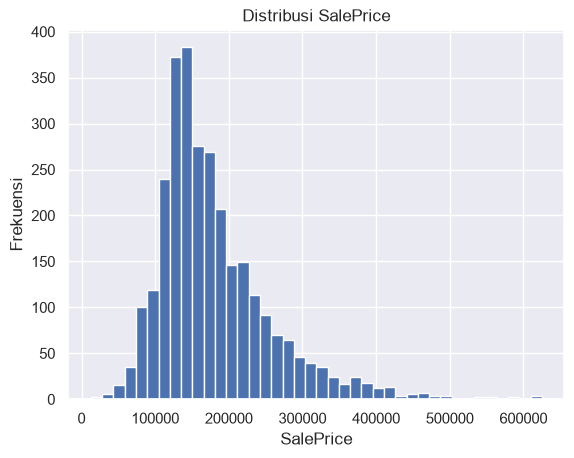

In [5]:
if "SalePrice" in df.columns:
    display(df["SalePrice"].describe())
    df["SalePrice"].hist(bins=40)
    plt.title("Distribusi SalePrice")
    plt.xlabel("SalePrice")
    plt.ylabel("Frekuensi")
    plt.show()
else:
    print("Kolom SalePrice tidak ditemukan; periksa nama kolom dataset.")

## 5. One-hot encoding untuk fitur kategorikal

Model numerik sering memerlukan kategori diubah menjadi kolom indikator. `drop_first=True` menghilangkan satu kategori acuan dari setiap fitur kategorikal untuk mengurangi redundansi pada model tertentu. Kita membuat salinan agar data asli tetap tersedia.

In [6]:
categorical_cols = df.select_dtypes(include=["object", "category"]).columns.tolist()
print("Jumlah fitur kategorikal:", len(categorical_cols))
print(categorical_cols[:15])
df_encoded = pd.get_dummies(df, columns=categorical_cols, drop_first=True, dtype=int)
print("Ukuran setelah encoding:", df_encoded.shape)
display(df_encoded.head())

Jumlah fitur kategorikal: 43
['MS Zoning', 'Street', 'Alley', 'Lot Shape', 'Land Contour', 'Utilities', 'Lot Config', 'Land Slope', 'Neighborhood', 'Condition 1', 'Condition 2', 'Bldg Type', 'House Style', 'Roof Style', 'Roof Matl']
Ukuran setelah encoding: (2925, 261)


C:\Users\ezza fisabii\AppData\Local\Temp\ipykernel_10744\1072013477.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include=["object", "category"]).columns.tolist()


,Order,PID,MS SubClass,Lot Frontage,Lot Area,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Mas Vnr Area,...,Sale Type_ConLw,Sale Type_New,Sale Type_Oth,Sale Type_VWD,Sale Type_WD,Sale Condition_AdjLand,Sale Condition_Alloca,Sale Condition_Family,Sale Condition_Normal,Sale Condition_Partial
0,1,526301100,20,141.0,31770,6,5,1960,1960,112.0,...,0,0,0,0,1,0,0,0,1,0
1,2,526350040,20,80.0,11622,5,6,1961,1961,0.0,...,0,0,0,0,1,0,0,0,1,0
2,3,526351010,20,81.0,14267,6,6,1958,1958,108.0,...,0,0,0,0,1,0,0,0,1,0
3,4,526353030,20,93.0,11160,7,5,1968,1968,0.0,...,0,0,0,0,1,0,0,0,1,0
4,5,527105010,60,74.0,13830,5,5,1997,1998,0.0,...,0,0,0,0,1,0,0,0,1,0


## 6. Mengidentifikasi fitur numerik yang menceng (skewed)

Skewness membantu melihat apakah distribusi fitur tidak simetris. Transformasi log hanya cocok untuk nilai positif; di sini digunakan `log1p`, yaitu log(1+x), untuk fitur yang nilainya tidak negatif.

In [7]:
numeric_cols = df.select_dtypes(include=[np.number]).columns
skewness = df[numeric_cols].skew(numeric_only=True).sort_values(key=lambda s: s.abs(), ascending=False)
display(skewness.head(15).to_frame("skewness"))

,skewness
Misc Val,22.225015
Pool Area,18.743766
Lot Area,13.200004
Low Qual Fin SF,12.107629
3Ssn Porch,11.393854
Kitchen AbvGr,4.309573
BsmtFin SF 2,4.135900
Enclosed Porch,4.010586
Bsmt Half Bath,3.965970
Screen Porch,3.953495


In [8]:
skew_limit = 0.75
log_candidates = [
    col for col in numeric_cols
    if col != "SalePrice" and df[col].notna().all() and (df[col] >= 0).all() and abs(df[col].skew()) > skew_limit
]
print("Kandidat log1p:", log_candidates[:20])
df_transformed = df.copy()
for col in log_candidates:
    df_transformed[col + "_log1p"] = np.log1p(df_transformed[col])
display(df_transformed[[c for c in df_transformed.columns if c.endswith("_log1p")]].head())

Kandidat log1p: ['MS SubClass', 'Lot Area', '1st Flr SF', '2nd Flr SF', 'Low Qual Fin SF', 'Gr Liv Area', 'Kitchen AbvGr', 'Wood Deck SF', 'Open Porch SF', 'Enclosed Porch', '3Ssn Porch', 'Screen Porch', 'Pool Area', 'Misc Val']


,MS SubClass_log1p,Lot Area_log1p,1st Flr SF_log1p,2nd Flr SF_log1p,Low Qual Fin SF_log1p,Gr Liv Area_log1p,Kitchen AbvGr_log1p,Wood Deck SF_log1p,Open Porch SF_log1p,Enclosed Porch_log1p,3Ssn Porch_log1p,Screen Porch_log1p,Pool Area_log1p,Misc Val_log1p
0,3.044522,10.366309,7.412764,0.000000,0.0,7.412764,0.693147,5.351858,4.143135,0.0,0.0,0.000000,0.0,0.000000
1,3.044522,9.360741,6.799056,0.000000,0.0,6.799056,0.693147,4.948760,0.000000,0.0,0.0,4.795791,0.0,0.000000
2,3.044522,9.565775,7.192934,0.000000,0.0,7.192934,0.693147,5.976351,3.610918,0.0,0.0,0.000000,0.0,9.433564
3,3.044522,9.320181,7.654917,0.000000,0.0,7.654917,0.693147,0.000000,0.000000,0.0,0.0,0.000000,0.0,0.000000
4,4.110874,9.534668,6.834109,6.553933,0.0,7.396335,0.693147,5.361292,3.555348,0.0,0.0,0.000000,0.0,0.000000


## 7. Membuat fitur interaksi dan polinomial

Fitur interaksi merepresentasikan gabungan dua fitur. Contoh di bawah menggunakan `Overall Qual` dan `Gr Liv Area` jika keduanya tersedia. Gunakan fitur yang relevan dan evaluasi dengan validasi model sebelum menyimpulkan bahwa fitur baru memperbaiki prediksi.

In [9]:
if {"Overall Qual", "Gr Liv Area"}.issubset(df.columns):
    df["Quality_x_LivingArea"] = df["Overall Qual"] * df["Gr Liv Area"]
    display(df[["Overall Qual", "Gr Liv Area", "Quality_x_LivingArea"]].head())

,Overall Qual,Gr Liv Area,Quality_x_LivingArea
0,6,1656,9936
1,5,896,4480
2,6,1329,7974
3,7,2110,14770
4,5,1629,8145


In [10]:
features = [col for col in ["Lot Area", "Overall Qual"] if col in df.columns]
if len(features) == 2:
    poly = PolynomialFeatures(degree=2, include_bias=False)
    poly_array = poly.fit_transform(df[features].fillna(df[features].median()))
    poly_df = pd.DataFrame(poly_array, columns=poly.get_feature_names_out(features), index=df.index)
    display(poly_df.head())
else:
    print("Fitur Lot Area dan Overall Qual tidak tersedia bersama-sama.")

,Lot Area,Overall Qual,Lot Area^2,Lot Area Overall Qual,Overall Qual^2
0,31770.0,6.0,1.009333e+09,190620.0,36.0
1,11622.0,5.0,1.350709e+08,58110.0,25.0
2,14267.0,6.0,2.035473e+08,85602.0,36.0
3,11160.0,7.0,1.245456e+08,78120.0,49.0
4,13830.0,5.0,1.912689e+08,69150.0,25.0


## 8. Kesimpulan

- Pemeriksaan awal membantu memahami tipe data dan nilai hilang.
- One-hot encoding mengubah kategori menjadi fitur numerik.
- Transformasi log dapat mengurangi kemencengan distribusi pada fitur non-negatif tertentu.
- Fitur interaksi dan polinomial dapat menangkap hubungan yang lebih kompleks.
- Fitur tambahan tidak otomatis membuat model lebih baik; bandingkan performa pada data validasi.